## Setup: imports and data folder

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("healthcare_ecosystem_lab_data")
DATA.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
print("Teaching files:", DATA.resolve())

Teaching files: D:\bennett\Healthcare\module 1\lab1\healthcare_ecosystem_lab_data


## Create synthetic data files

In [2]:
patients = pd.DataFrame([
    ("P001", 1980), ("P002", 1992), ("P003", 1975), ("P004", 2000)
], columns=["patient_id", "birth_year"])
encounters = pd.DataFrame([
    ("E001", "P001", "2026-01-10T09:00:00+05:30", "outpatient"),
    ("E002", "P001", "2026-02-10T10:00:00+05:30", "outpatient"),
    ("E003", "P002", "2026-01-15T11:00:00+05:30", "outpatient"),
    ("E004", "P003", "2026-01-20T09:00:00+05:30", "outpatient"),
    ("E005", "P003", "2026-03-01T09:00:00+05:30", "outpatient"),
    ("E006", "P004", "2025-12-20T09:00:00+05:30", "outpatient")
], columns=["encounter_id", "patient_id", "start", "type"])
observations = pd.DataFrame([
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O002", "E001", "temperature", 37, "Cel", "2026-01-10T09:12:00+05:30"),
    ("O003", "E002", "heart_rate", None, "beats/min", "2026-02-10T10:10:00+05:30"),
    ("O004", "E003", "temperature", 98.6, "[degF]", "2026-01-15T11:10:00+05:30"),
    ("O005", "E004", "heart_rate", 84, "beats/min", "2026-01-20T09:10:00+05:30"),
    ("O006", "E005", "heart_rate", 80, "beats/min", "2026-03-01T09:10:00+05:30")
], columns=["observation_id", "encounter_id", "code", "value", "unit", "effective_time"])
notes = pd.DataFrame([
    ("N001", "P001", "E001", "No history of diabetes. Patient reports reduced activity."),
    ("N002", "P001", "E002", "Follow-up visit. Further assessment planned."),
    ("N003", "P002", "E003", "Family history of diabetes; patient history not established.")
], columns=["note_id", "patient_id", "encounter_id", "text"])
times = pd.date_range("2026-01-10T00:00:00+05:30", periods=24, freq="h")
wearable = pd.DataFrame({"patient_id": "P001", "time": times,
                         "steps": [0,0,0,0,0,20,100,250,300,150,80,120,
                                   200,180,90,140,220,400,350,200,100,40,10,0]})
# Deliberately omit six expected hourly samples. A gap is not a zero.
wearable = wearable.drop(index=range(12,18)).reset_index(drop=True)
for name, frame in {"patients":patients, "encounters":encounters,
                    "observations":observations, "notes":notes, "wearable":wearable}.items():
    frame.to_csv(DATA / f"{name}.csv", index=False)

# Small R4-style collection Bundle, separate from the intentionally messy CSV.
# Educational examples; no formal FHIR/profile validator is run here.
resources = [{"resourceType":"Patient", "id":p} for p in patients.patient_id]
for row in encounters.itertuples():
    resources.append({"resourceType":"Encounter", "id":row.encounter_id,
        "status":"finished", "class":{"system":"http://terminology.hl7.org/CodeSystem/v3-ActCode",
        "code":"AMB"}, "subject":{"reference":f"Patient/{row.patient_id}"},
        "period":{"start":row.start}})
for oid, pid, eid, value, time in [
    ("O001","P001","E001",78,"2026-01-10T09:10:00+05:30"),
    ("O005","P003","E004",84,"2026-01-20T09:10:00+05:30")]:
    resources.append({"resourceType":"Observation", "id":oid, "status":"final",
        "code":{"coding":[{"system":"http://loinc.org", "code":"8867-4", "display":"Heart rate"}]},
        "subject":{"reference":f"Patient/{pid}"},
        "encounter":{"reference":f"Encounter/{eid}"}, "effectiveDateTime":time,
        "valueQuantity":{"value":value, "unit":"beats/minute",
        "system":"http://unitsofmeasure.org", "code":"/min"}})
bundle = {"resourceType":"Bundle", "type":"collection", "entry":[
    {"fullUrl":f"https://example.org/fhir/{r['resourceType']}/{r['id']}", "resource":r}
    for r in resources]}
(DATA / "patient_bundle.json").write_text(json.dumps(bundle, indent=2), encoding="utf-8")
print("Created five CSV files and one JSON file.")

Created five CSV files and one JSON file.


## 1. Load and inspect the tables

In [3]:
tables = {name: pd.read_csv(DATA / f"{name}.csv")
          for name in ["patients", "encounters", "observations", "notes", "wearable"]}

for name, frame in tables.items():
    print(name, frame.shape)
    display(frame.head(3))
    
patients, encounters, observations, notes, wearable = [tables[n] for n in tables]
encounters["start"] = pd.to_datetime(encounters["start"], utc=True)
observations["effective_time"] = pd.to_datetime(observations["effective_time"], utc=True)
wearable["time"] = pd.to_datetime(wearable["time"], utc=True)

patients (4, 2)


,patient_id,birth_year
0,P001,1980
1,P002,1992
2,P003,1975


encounters (6, 4)


,encounter_id,patient_id,start,type
0,E001,P001,2026-01-10T09:00:00+05:30,outpatient
1,E002,P001,2026-02-10T10:00:00+05:30,outpatient
2,E003,P002,2026-01-15T11:00:00+05:30,outpatient


observations (7, 6)


,observation_id,encounter_id,code,value,unit,effective_time
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
1,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
2,O002,E001,temperature,37.0,Cel,2026-01-10T09:12:00+05:30


notes (3, 4)


,note_id,patient_id,encounter_id,text
0,N001,P001,E001,No history of diabetes. Patient reports reduce...
1,N002,P001,E002,Follow-up visit. Further assessment planned.
2,N003,P002,E003,Family history of diabetes; patient history no...


wearable (18, 3)


,patient_id,time,steps
0,P001,2026-01-10 00:00:00+05:30,0
1,P001,2026-01-10 01:00:00+05:30,0
2,P001,2026-01-10 02:00:00+05:30,0


## 2. Quality checks

In [4]:
print("Exact duplicate observation rows:", observations.duplicated().sum())
print("Repeated observation IDs:", observations.observation_id.duplicated().sum())
display(observations.isna().sum().rename("missing_count").to_frame())
display(observations.groupby(["code", "unit"]).size().rename("rows").reset_index())
display(notes.assign(keyword_diabetes=notes.text.str.contains("diabetes", case=False)))

Exact duplicate observation rows: 1
Repeated observation IDs: 1


,missing_count
observation_id,0
encounter_id,0
code,0
value,1
unit,0
effective_time,0


,code,unit,rows
0,heart_rate,beats/min,5
1,temperature,Cel,1
2,temperature,[degF],1


,note_id,patient_id,encounter_id,text,keyword_diabetes
0,N001,P001,E001,No history of diabetes. Patient reports reduce...,True
1,N002,P001,E002,Follow-up visit. Further assessment planned.,False
2,N003,P002,E003,Family history of diabetes; patient history no...,True


## 2. Data dictionary and temperature in Celsius

In [5]:
# Exercise: create a dictionary. Add at least eight rows.
data_dictionary = pd.DataFrame([
    ["patients", "patient_id", "person ID", "str", "", "primary key", "not allowed"],
    ["patients", "birth_year", "birth year", "int", "year", "", "age unknown"],
    ["encounters", "encounter_id", "visit ID", "str", "", "primary key", "not allowed"],
    ["encounters", "patient_id", "patient of visit", "str", "", "foreign key", "cannot link"],
    ["encounters", "start", "visit start time", "datetime", "", "", "time unknown"],
    ["observations", "observation_id", "measurement ID", "str", "", "primary key", "not allowed"],
    ["observations", "encounter_id", "visit of measurement", "str", "", "foreign key", "cannot link"],
    ["observations", "value", "measured value", "float", "see unit", "", "not recorded (not 0)"],
], columns=["file", "column", "meaning", "type", "unit", "key_role", "missing_meaning"])
display(data_dictionary)

# Exercise: temperature rows in Celsius (in a copy, keeping value and unit).
temp = observations[observations.code == "temperature"].copy()
temp["value_celsius"] = temp.value.where(temp.unit == "Cel", (temp.value - 32) * 5 / 9)
display(temp)


,file,column,meaning,type,unit,key_role,missing_meaning
0,patients,patient_id,person ID,str,,primary key,not allowed
1,patients,birth_year,birth year,int,year,,age unknown
2,encounters,encounter_id,visit ID,str,,primary key,not allowed
3,encounters,patient_id,patient of visit,str,,foreign key,cannot link
4,encounters,start,visit start time,datetime,,,time unknown
5,observations,observation_id,measurement ID,str,,primary key,not allowed
6,observations,encounter_id,visit of measurement,str,,foreign key,cannot link
7,observations,value,measured value,float,see unit,,not recorded (not 0)


,observation_id,encounter_id,code,value,unit,effective_time,value_celsius
2,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,37.0
4,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,37.0


## 2. Remove exact duplicates

In [6]:
clean_obs = observations.drop_duplicates().copy()
assert clean_obs.observation_id.is_unique
assert patients.patient_id.is_unique
assert encounters.encounter_id.is_unique
print("Raw rows:", len(observations), "After exact deduplication:", len(clean_obs))

Raw rows: 7 After exact deduplication: 6


## 3. Link observations to encounters and patients

In [7]:
encounter_patient = encounters.merge(patients, on="patient_id", how="left",
                                      validate="many_to_one", indicator=True)
assert encounter_patient["_merge"].eq("both").all()
encounter_patient = encounter_patient.drop(columns="_merge")
linked = clean_obs.merge(encounter_patient, on="encounter_id", how="left",
                         validate="many_to_one", indicator=True)
assert linked["_merge"].eq("both").all()
assert len(linked) == len(clean_obs)
linked = linked.drop(columns="_merge")
display(linked)
print("Rows:", len(linked), "Distinct patients:", linked.patient_id.nunique())

,observation_id,encounter_id,code,value,unit,effective_time,patient_id,start,type,birth_year
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10 03:40:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
1,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
2,O003,E002,heart_rate,NaN,beats/min,2026-02-10 04:40:00+00:00,P001,2026-02-10 04:30:00+00:00,outpatient,1980
3,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,P002,2026-01-15 05:30:00+00:00,outpatient,1992
4,O005,E004,heart_rate,84.0,beats/min,2026-01-20 03:40:00+00:00,P003,2026-01-20 03:30:00+00:00,outpatient,1975
5,O006,E005,heart_rate,80.0,beats/min,2026-03-01 03:40:00+00:00,P003,2026-03-01 03:30:00+00:00,outpatient,1975


Rows: 6 Distinct patients: 3


## 3. Wrong join vs correct notes join

In [8]:
# Demonstrate multiplication by linking independent encounter and note rows only by patient.
bad_join = encounters.merge(notes[["patient_id", "note_id"]], on="patient_id", how="left")
display(bad_join.loc[bad_join.patient_id.eq("P001"), ["patient_id", "encounter_id", "note_id"]])

# Exercise: join notes to encounters using encounter_id.
good_join = encounters.merge(notes[["encounter_id", "note_id"]], on="encounter_id",
                             how="left", validate="one_to_many")
display(good_join[good_join.patient_id == "P001"])


,patient_id,encounter_id,note_id
0,P001,E001,N001
1,P001,E001,N002
2,P001,E002,N001
3,P001,E002,N002


,encounter_id,patient_id,start,type,note_id
0,E001,P001,2026-01-10 03:30:00+00:00,outpatient,N001
1,E002,P001,2026-02-10 04:30:00+00:00,outpatient,N002


## 4. Cohort: patients with 2+ encounters

In [9]:
window_start = pd.Timestamp("2026-01-01", tz="Asia/Kolkata").tz_convert("UTC")
window_end = pd.Timestamp("2026-03-01", tz="Asia/Kolkata").tz_convert("UTC")

in_window = encounters[(encounters.start >= window_start) & (encounters.start < window_end)]
counts = in_window.groupby("patient_id").encounter_id.nunique()
cohort = counts[counts >= 2].reset_index()
display(cohort)


,patient_id,encounter_id
0,P001,2


## 5. Read FHIR observations

In [10]:
bundle_loaded = json.loads((DATA / "patient_bundle.json").read_text(encoding="utf-8"))
resource_index = {f"{e['resource']['resourceType']}/{e['resource']['id']}": e["resource"]
                  for e in bundle_loaded["entry"]}
fhir_rows = []
for resource in resource_index.values():
    if resource["resourceType"] != "Observation":
        continue
    patient_ref = resource["subject"]["reference"]
    encounter_ref = resource["encounter"]["reference"]
    assert patient_ref in resource_index and encounter_ref in resource_index
    assert resource_index[encounter_ref]["subject"]["reference"] == patient_ref
    coding = next(c for c in resource["code"]["coding"] if c["system"] == "http://loinc.org")
    q = resource["valueQuantity"]
    fhir_rows.append({"observation_id":resource["id"],
        "patient_id":patient_ref.split("/")[-1], "encounter_id":encounter_ref.split("/")[-1],
        "loinc_code":coding["code"], "value":q["value"], "ucum_code":q["code"],
        "effective_time":resource["effectiveDateTime"]})
fhir_frame = pd.DataFrame(fhir_rows)
fhir_frame["effective_time"] = pd.to_datetime(fhir_frame["effective_time"], utc=True)
display(fhir_frame)

,observation_id,patient_id,encounter_id,loinc_code,value,ucum_code,effective_time
0,O001,P001,E001,8867-4,78,/min,2026-01-10 03:40:00+00:00
1,O005,P003,E004,8867-4,84,/min,2026-01-20 03:40:00+00:00


## 5. Compare FHIR with CSV

In [11]:
# Explicit mappings apply only to the codes/units in this teaching fixture.
comparison_source = linked.copy()
comparison_source["loinc_code"] = comparison_source.code.map({"heart_rate":"8867-4"})
comparison_source["ucum_code"] = comparison_source.unit.map({"beats/min":"/min"})
comparison = fhir_frame.merge(comparison_source, on="observation_id", how="left",
                              suffixes=("_fhir", "_csv"), validate="one_to_one", indicator=True)
assert comparison["_merge"].eq("both").all()
for field in ["patient_id", "encounter_id", "loinc_code", "value", "ucum_code", "effective_time"]:
    assert comparison[f"{field}_fhir"].eq(comparison[f"{field}_csv"]).all(), field
print("All two FHIR observations agree with their CSV counterparts on identity, code, value, unit, and time.")

All two FHIR observations agree with their CSV counterparts on identity, code, value, unit, and time.


## 6. Patient timeline and wearable gaps

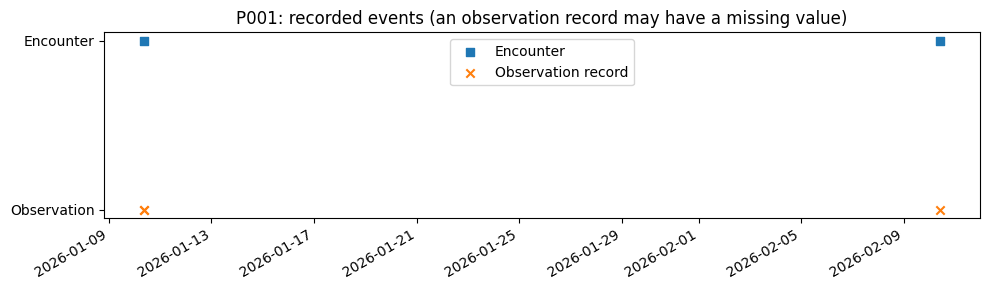

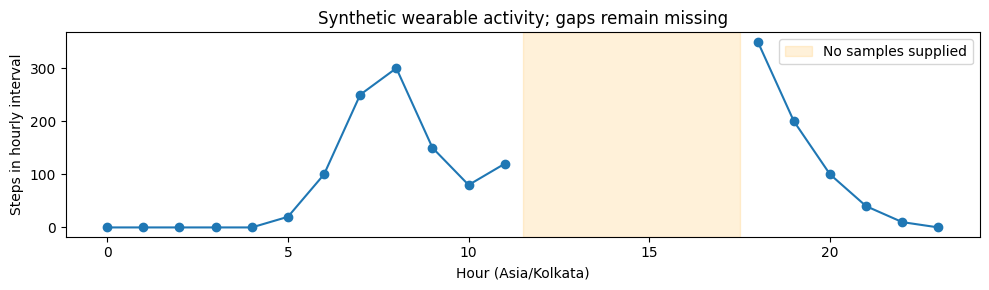

Missing expected hourly samples: 6


In [12]:
p1_encounters = encounters.loc[encounters.patient_id.eq("P001")]
p1_obs = linked.loc[linked.patient_id.eq("P001")]
fig, ax = plt.subplots(figsize=(10, 3))
ax.scatter(p1_encounters.start.dt.tz_convert("Asia/Kolkata"), [1]*len(p1_encounters), label="Encounter", marker="s")
ax.scatter(p1_obs.effective_time.dt.tz_convert("Asia/Kolkata"), [0]*len(p1_obs), label="Observation record", marker="x")
ax.set_yticks([0, 1], ["Observation", "Encounter"])
ax.set_title("P001: recorded events (an observation record may have a missing value)")
ax.legend(loc="upper center")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

expected = pd.date_range("2026-01-10", periods=24, freq="h", tz="Asia/Kolkata")
series = wearable.set_index("time")["steps"].tz_convert("Asia/Kolkata").reindex(expected)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(series.index.hour, series.values, marker="o")
ax.axvspan(11.5, 17.5, alpha=0.15, color="orange", label="No samples supplied")
ax.set(xlabel="Hour (Asia/Kolkata)", ylabel="Steps in hourly interval", title="Synthetic wearable activity; gaps remain missing")
ax.legend()
plt.tight_layout()
plt.show()
print("Missing expected hourly samples:", series.isna().sum())

## Reference checks

In [13]:
temperature_answer = clean_obs.loc[clean_obs.code.eq("temperature")].copy()
assert temperature_answer.unit.isin(["Cel", "[degF]"]).all()
temperature_answer["value_celsius"] = temperature_answer.apply(
    lambda r: (r.value - 32) * 5 / 9 if r.unit == "[degF]" else r.value, axis=1)
display(temperature_answer)

correct_notes_answer = encounters.merge(notes[["encounter_id", "note_id", "text"]],
                                        on="encounter_id", how="left", validate="one_to_many")
assert len(correct_notes_answer.loc[correct_notes_answer.patient_id.eq("P001")]) == 2

eligible_answer = encounters.loc[encounters.start.ge(window_start) & encounters.start.lt(window_end)]
counts_answer = eligible_answer.groupby("patient_id").encounter_id.nunique()
cohort_answer = counts_answer[counts_answer.ge(2)].rename("encounter_count").reset_index()
display(cohort_answer)
assert cohort_answer.patient_id.tolist() == ["P001"]
assert len(clean_obs) == 6
assert linked.patient_id.nunique() == 3
assert series.isna().sum() == 6
print("Reference checks passed.")

,observation_id,encounter_id,code,value,unit,effective_time,value_celsius
2,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,37.0
4,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,37.0


,patient_id,encounter_count
0,P001,2


Reference checks passed.


**Submitted by:** Anshupadhyay1419